In [13]:
import pandas as pd

ds = pd.read_csv("./datasets/Mall_Customers.csv")
ds

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [14]:
# Preprocessing - Encoding All the Labels
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

ds["Genre"] = le.fit_transform(ds["Genre"])

X = ds[["Spending Score (1-100)", "Annual Income (k$)"]]

In [15]:
from sklearn.cluster import AgglomerativeClustering, KMeans

model1 = AgglomerativeClustering(n_clusters=10)
label1 = model1.fit_predict(X)

model2 = KMeans(n_clusters = 10)
label2 = model2.fit_predict(X)


In [16]:
# Metrics
from sklearn.metrics import silhouette_score

print("---- Agglomerative Clustering ----")
print(f"sscore : {silhouette_score(X, label1)}")


print("---- KMeans Clustering ----")
print(f"Inertia : {model2.inertia_}")
print(f"sscore : {silhouette_score(X, label2)}")

---- Agglomerative Clustering ----
sscore : 0.4342656377895271
---- KMeans Clustering ----
Inertia : 21239.945499108733
sscore : 0.42686843737954056


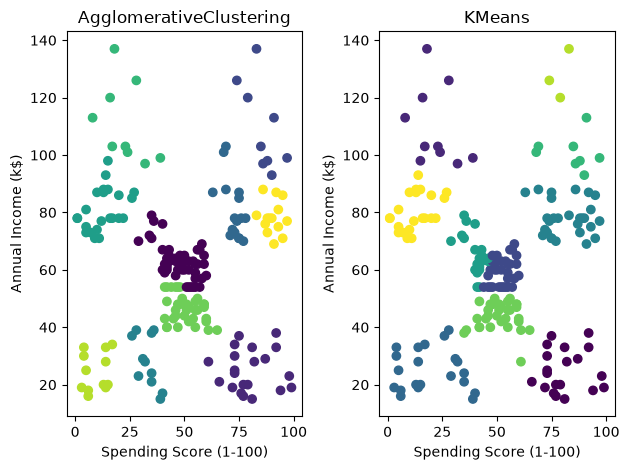

In [17]:
import matplotlib.pyplot as plt

plt.subplot(1, 2, 1)
plt.scatter(X["Spending Score (1-100)"], X["Annual Income (k$)"], c=label1)
plt.title("AgglomerativeClustering")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Annual Income (k$)")

plt.subplot(1, 2, 2)
plt.scatter(X["Spending Score (1-100)"], X["Annual Income (k$)"], c=label2)
plt.title("KMeans")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Annual Income (k$)")

plt.tight_layout()
plt.show()